<a href="https://colab.research.google.com/github/janpeter19/BPL_CHO_Fedbatch/blob/main/BPL_TEST2_Batch_oms_colab_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BPL_TEST2_Batch script with OMSimulator

The key library OMSimulator is installed.

After the installation a small application BPL_TEST2_Batch is loaded and run. You can continue with this example if you like.

In [ ]:
!lsb_release -a # Actual VM Ubuntu version used by Google

No LSB modules are available.
Distributor ID:	Ubuntu
Description:	Ubuntu 24.04.5 LTS
Release:	24.04
Codename:	noble


In [ ]:
!python --version

Python 3.13.18


In [ ]:
%pip install -q uv

In [ ]:
!uv pip install OMSimulator

Using Python 3.13.18 environment at: /usr
Resolved 7 packages in 219ms
Prepared 1 package in 4.63s
Installed 1 package in 3ms
 + omsimulator==3.0.0.post198


In [ ]:
!uv pip install --system git+https://github.com/janpeter19/FMU_explore.git@v1.2.6

Using Python 3.13.18 environment at: /usr
Resolved 1 package in 437ms
Prepared 1 package in 2.42s
Installed 1 package in 1ms
 + fmu-explore==1.2.6 (from git+https://github.com/janpeter19/FMU_explore.git@573ae8b5a2daf5d983a5cf2d98abbd78ab7da18e)


In [ ]:
!uv pip install DyMat

Using Python 3.13.18 environment at: /usr
Resolved 1 package in 2.16s
Prepared 1 package in 1.59s
Installed 1 package in 3ms
 + dymat==0.7


# BPL_TEST2_Batch setup


Now specific installation and the run simulations. Start with connecting to Github. Then upload the two files:

* FMU - BPL_TEST2_Batch_linux_om_me.fmu
* Setup-file - BPL_TEST2_Batch_oms.py
* Setup-file - BPL_TEST2_Batch_oms_explore.py

In [ ]:
%%bash
git clone https://github.com/janpeter19/BPL_TEST2_Batch

Cloning into 'BPL_TEST2_Batch'...


In [ ]:
%cd BPL_TEST2_Batch

/content/BPL_TEST2_Batch


In [ ]:
# Import the application model and context variables
from BPL_TEST2_Batch_oms import*

Linux - run FMU pre-compiled OpenModelica


In [ ]:
# Import the general FMU_explore functions ana adapt them to the application
from fmu_explore_oms import AdaptWith

Application = AdaptWith(parValue, parLocation, parCheck, \
                        fmu_model, fmu_process_diagram, \
                        MSL_usage, MSL_version, BPL_version, \
                        options, simulationTime, timeDiscreteStates, \
                        diagrams, ax, lines)

par = Application.par
init = Application.init
simu = Application.simu
show = Application.show

resetPen = Application.resetPen
process_diagram = Application.process_diagram

describe_MSL = Application.describe_MSL
FMU_explore_info = Application.FMU_explore_info
system_info = Application.system_info
SDG = Application.SDG

In [ ]:
run -i BPL_TEST2_Batch_oms_explore.py


Model for the process has been setup. Key commands:
 - par()       - change of parameters and initial values
 - init()      - change initial values only
 - simu()      - simulate and plot
 - newplot()   - make a new plot
 - show()      - show plot from previous simulation
 - disp()      - display parameters and initial values from the last simulation
 - describe()  - describe culture, broth, parameters, variables with values/units

Note that both disp() and describe() takes values from the last simulation
and the command process_diagram() brings up the main configuration

Brief information about a command by help(), eg help(simu)
Key system information is listed with the command system_info()


In [ ]:
%matplotlib inline
plt.rcParams['figure.figsize'] = [25/2.54, 20/2.54]

In [ ]:
import warnings
warnings.filterwarnings("ignore")

## BPL_TEST2_Batch - demo

No processDiagram.png file in the FMU, but try the file on disk.


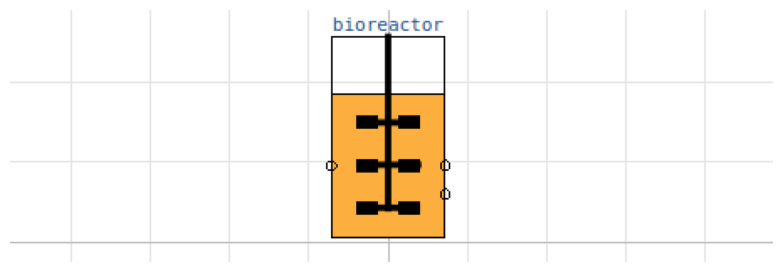

In [ ]:
process_diagram()

In [ ]:
#describe('process')


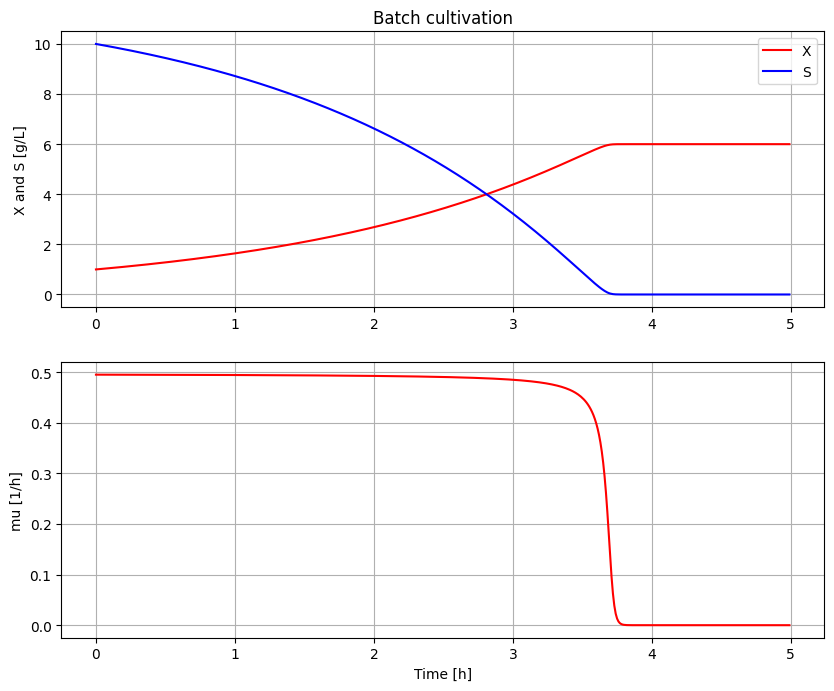

In [ ]:
# Simulation with default values of the process
newplot(plotType='TimeSeries')
simu()

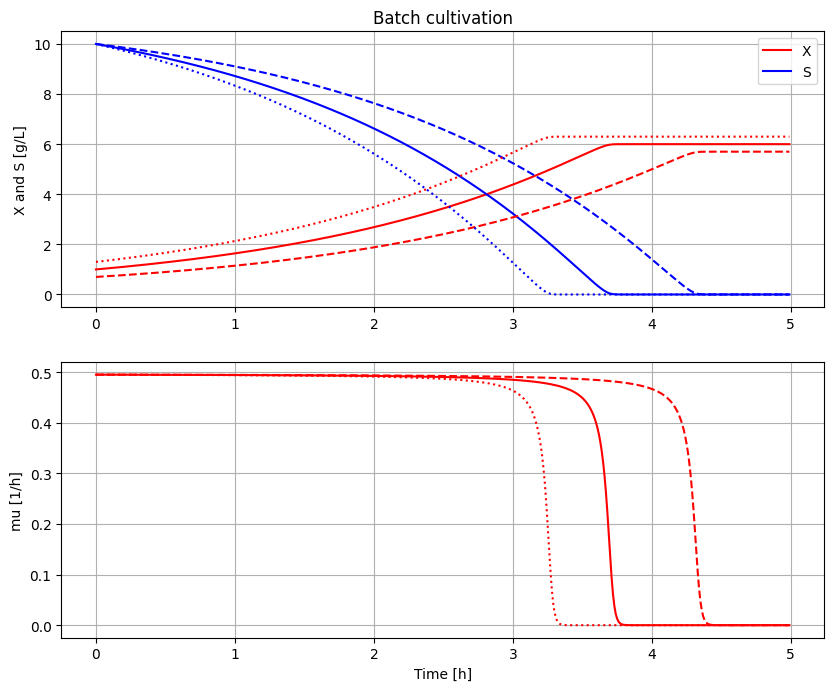

In [ ]:
# Simulation were initial value of biomass VX_0 is varied
newplot(plotType='TimeSeries')
for value in [1.0, 0.7, 1.3]:
  init(VX_start=value)
  simu()

# Restore default value of VX_start
init(VX_start=1.0)

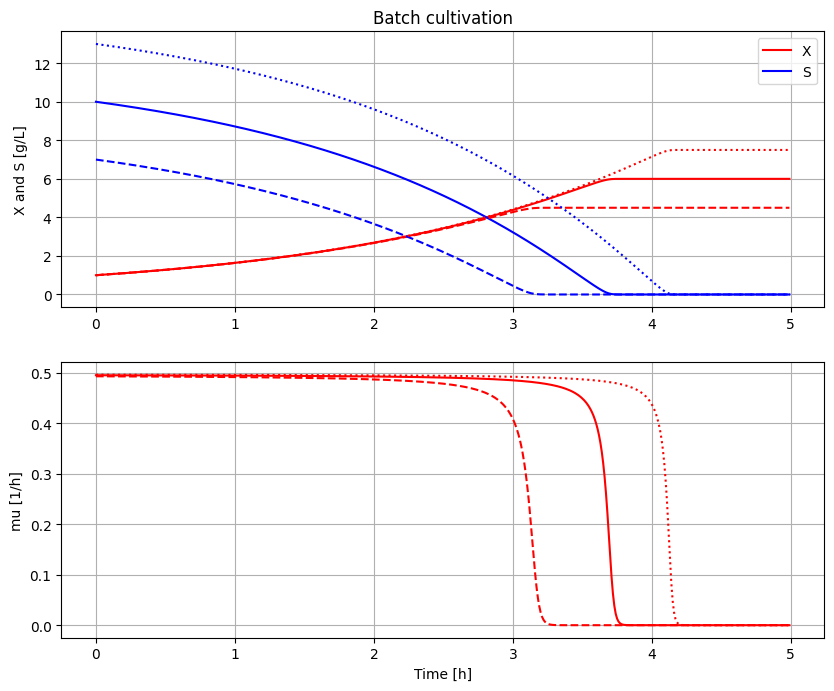

In [ ]:
# Simulation were initial value of substrate VS_0 is varied
newplot(plotType='TimeSeries')
for value in [10, 7, 13]:
  init(VS_start=value)
  simu()

# Restore default value of VS_start
init(VS_start=10)

In [ ]:
describe('MSL')

MSL: 4.1.0 - used components: none


In [ ]:
system_info()


System information
 -OS: Linux
 -Python: 3.13.18
 -Scipy: 1.16.3
 -OMSimulator: 3.0.0.post198
 -FMU by: OpenModelica Compiler OpenModelica 1.26.3~1-g7583224
 -FMI: 2.0
 -Type: me
 -Name: BPL.Examples_TEST2.Batch
 -Generated: 2026-04-11T11:35:27Z
 -MSL: 4.1.0
 -Description: Bioprocess Library version 2.3.2
 -Interaction: FMU_explore version 1.2.6


In [ ]:
!lsb_release -d

No LSB modules are available.
Description:	Ubuntu 24.04.5 LTS


In [ ]:
SDG()

In [ ]:
# Install OMSimulator in the notebook
import OMSimulator as oms
import DyMat

In [ ]:
# Useful mnmonics
parValue = Application.parValue
parLocation = Application.parLocation
fmu_model = Application.fmu_model
simulationTime = Application.simulationTime
options = Application.options

In [ ]:
# Make a new model even if there is one before
if 'model' in locals():
   #print('model exist')
   if isinstance(model, oms.fmu.FMU) and getattr(model, 'instanceName', None) is not None:
       model.delete()

model = oms.FMU(fmu_model)
model.instantiate()
#print('new model instantiated')

In [ ]:
# Set the logg file
model.setResultFile('sim_res.mat')
if options is not None:
    for command in options:
        eval(command)

In [ ]:
# Modify some parameter
parValue['Y'] = 0.3

In [ ]:
# Set parameters
for key in parValue.keys():
    model.setValue(parLocation[key], parValue[key])
model.setStopTime(simulationTime)

In [ ]:
# Simulation
model.initialize()
model.simulate()

In [ ]:
# Open up result file
temp = scipy.io.loadmat('sim_res.mat')
t = temp['data_2'][0];
sim_res = DyMat.DyMatFile('sim_res.mat')
Application.t = t
Application.sim_res = sim_res

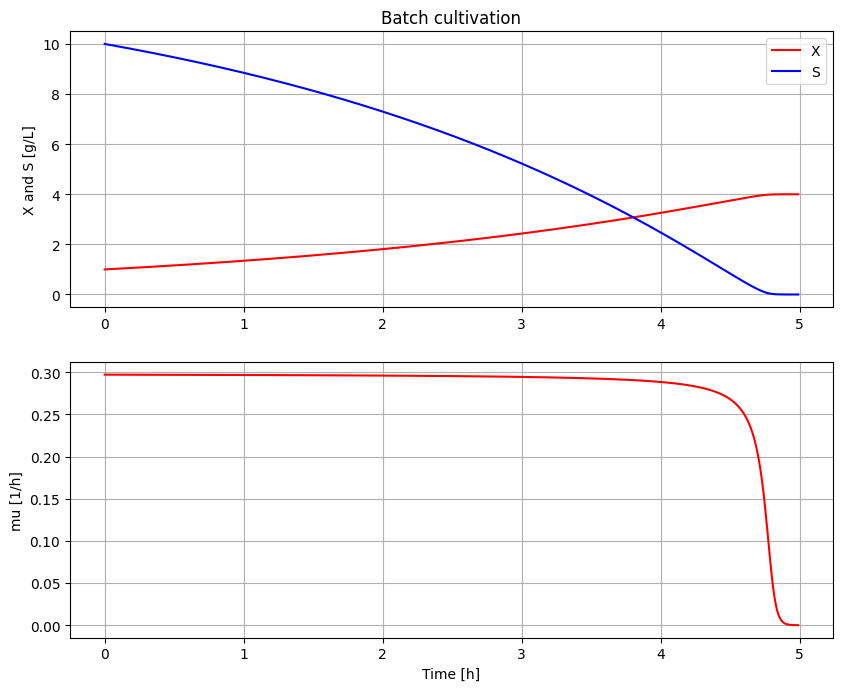

In [ ]:
# Plot
newplot()
show()

In [ ]:
# Read a parameter from the "active" model
model.getValue('bioreactor.culture.Y')


0.3